# Phase 2, Part A: noise-model mismatch experiments

What this notebook shows, in the order of the protocol (`report/mismatch_protocol.md`):

1. The two noise models and why a single AWGN sigma cannot describe Poisson-Gaussian (PG) noise
2. The three ways of choosing the sigma an AWGN method is told (rules A, B, C)
3. One image through every arm (what each arm actually feeds the denoiser)
4. The three inverse GATs (algebraic, closed form, exact unbiased)
5. The harness running live on a small grid
6. The full benchmark results (read from `results/phase2_results.csv`)

Arms: **M0** matched AWGN. **X0** AWGN with the same total variance as the PG case. **MM-A / MM-B / MM-C** PG data, method told sigma by rule A / B / C. **VST** GAT, denoise with sigma = 1, inverse GAT.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", message="Unable to import Axes3D")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from utils import load_dataset, load_config
from noise import (add_awgn, add_poisson_gaussian, alpha_from_peak, gat_forward,
                   sigma_equal_variance, sigma_blind, sigma_read_only)
from noise.diagnostics import inverse_bias_curve
from denoisers import denoise
from metrics import psnr
from experiments import ARMS, build_cases, params_for, run_experiments
from experiments.arms import Setting
from experiments.runner import vst_pipeline, apply_preset

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 10, "axes.labelsize": 9})
# categorical colours, fixed order per entity (never re-assigned between charts)
COL = {"X0": "#2a78d6", "MM-A": "#eb6834", "MM-B": "#1baf7a", "MM-C": "#eda100", "VST": "#e87ba4"}
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#dcdcd8", "#eb6834"])

cfg = load_config()
SEED = cfg["seed"]
set12 = load_dataset("set12", data_root=ROOT / cfg["data_root"])
print("seed", SEED, "| Set12 images:", len(set12), "| arms:", ARMS)

seed 2026 | Set12 images: 12 | arms: ('M0', 'X0', 'MM-A', 'MM-B', 'MM-C', 'VST')


## 1. The two noise models

AWGN adds the same noise everywhere. PG noise is Poisson (shot noise, variance grows with brightness) plus Gaussian read noise: `Var(z|x) = alpha*x + sigma_read^2`, with `alpha = 1/peak`. A low peak means a lot of shot noise.

Change the three variables below and re-run the cell.

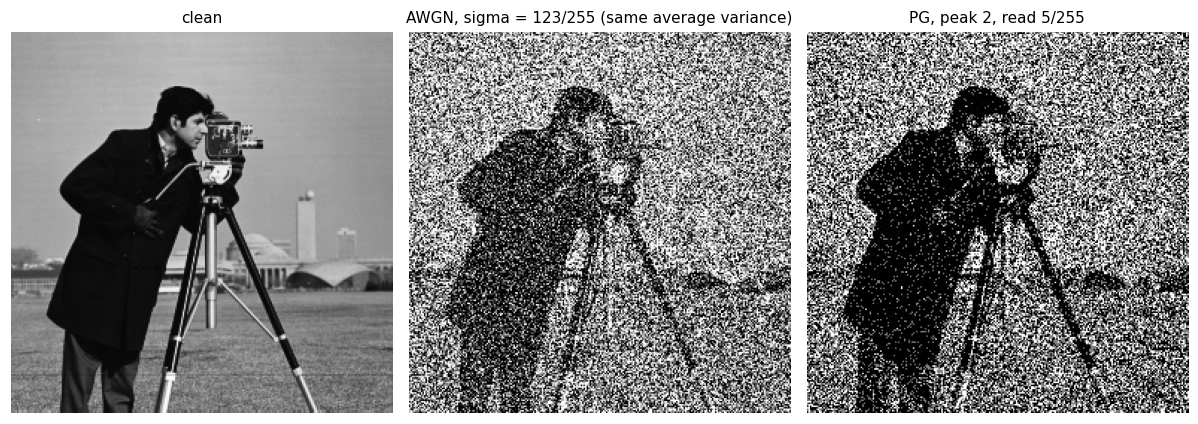

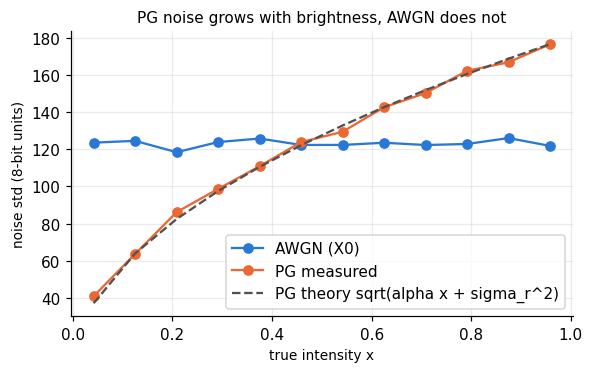

In [2]:
IMG_IDX = 0            # which Set12 image
PEAK = 2               # photon peak, 1 = very noisy ... 30 = mild
SIGMA_READ_255 = 5     # read noise in 8-bit units

name, x = set12[IMG_IDX]
alpha, sr = alpha_from_peak(PEAK), SIGMA_READ_255 / 255
sig_eq = sigma_equal_variance(x, alpha, sr)
rng = np.random.default_rng(0)
z_awgn = add_awgn(x, sig_eq, rng)
z_pg = add_poisson_gaussian(x, alpha, sr, rng)

fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
for a, im, t in zip(ax, [x, z_awgn, z_pg],
                    ["clean", f"AWGN, sigma = {sig_eq*255:.0f}/255 (same average variance)",
                     f"PG, peak {PEAK}, read {SIGMA_READ_255}/255"]):
    a.imshow(np.clip(im, 0, 1), cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off"); a.grid(False)
plt.tight_layout(); plt.show()

# noise std as a function of the true intensity
bins = np.linspace(0, 1, 13); mid = 0.5 * (bins[1:] + bins[:-1]); idx = np.digitize(x.ravel(), bins) - 1
def std_by_bin(z):
    n = (z - x).ravel()
    return np.array([n[idx == b].std() if (idx == b).sum() > 50 else np.nan for b in range(12)])
fig, a = plt.subplots(figsize=(5.5, 3.5))
a.plot(mid, std_by_bin(z_awgn) * 255, "o-", color=COL["X0"], label="AWGN (X0)")
a.plot(mid, std_by_bin(z_pg) * 255, "o-", color=COL["MM-A"], label="PG measured")
a.plot(mid, np.sqrt(alpha * mid + sr**2) * 255, "--", color="#52514e", label="PG theory sqrt(alpha x + sigma_r^2)")
a.set_xlabel("true intensity x"); a.set_ylabel("noise std (8-bit units)"); a.set_title("PG noise grows with brightness, AWGN does not"); a.legend()
plt.tight_layout(); plt.show()

## 2. Which sigma does an AWGN method get on PG data?

- **A (oracle, headline):** `sqrt(alpha*mean(x) + sigma_read^2)`, the AWGN level with the same average variance. Uses the clean image, only to set a fair level.
- **B (blind):** `estimate_sigma(z)` from the noisy image alone, what a practitioner would do.
- **C (naive):** the read noise only, ignoring shot noise (1/255 if it is 0).

In [3]:
rows = []
for p in [1, 2, 5, 10, 30]:
    for r in [0, 5, 10]:
        a_ = alpha_from_peak(p); zz = add_poisson_gaussian(x, a_, r / 255, np.random.default_rng(1))
        rows.append({"peak": p, "read (/255)": r, "A: sigma_eq": 255 * sigma_equal_variance(x, a_, r / 255),
                     "B: blind": 255 * sigma_blind(zz), "C: read only": 255 * sigma_read_only(r / 255)})
pd.DataFrame(rows).round(1).set_index(["peak", "read (/255)"])

A: sigma_eq  B: blind  C: read only
peak read (/255)                                     
1    0                  174.0     152.7           1.0
     5                  174.1     137.8           5.0
     10                 174.3     137.7          10.0
2    0                  123.0     106.3           1.0
     5                  123.1     101.0           5.0
     10                 123.4     101.6          10.0
5    0                   77.8      65.4           1.0
     5                   78.0      64.5           5.0
     10                  78.5      65.5          10.0
10   0                   55.0      47.6           1.0
     5                   55.2      48.1           5.0
     10                  55.9      49.2          10.0
30   0                   31.8      27.5           1.0
     5                   32.2      28.2           5.0
     10                  33.3      30.2          10.0

## 3. One image through every arm

Each arm gets its own noisy input and its own `sigma_assumed`. MM-A, MM-B, MM-C and VST share exactly the same noisy image (paired comparison). VST is told sigma = 1 because the GAT output has unit noise std. Set `METHOD` to any implemented method (`mean`, `gaussian`, `median`, `wiener`).

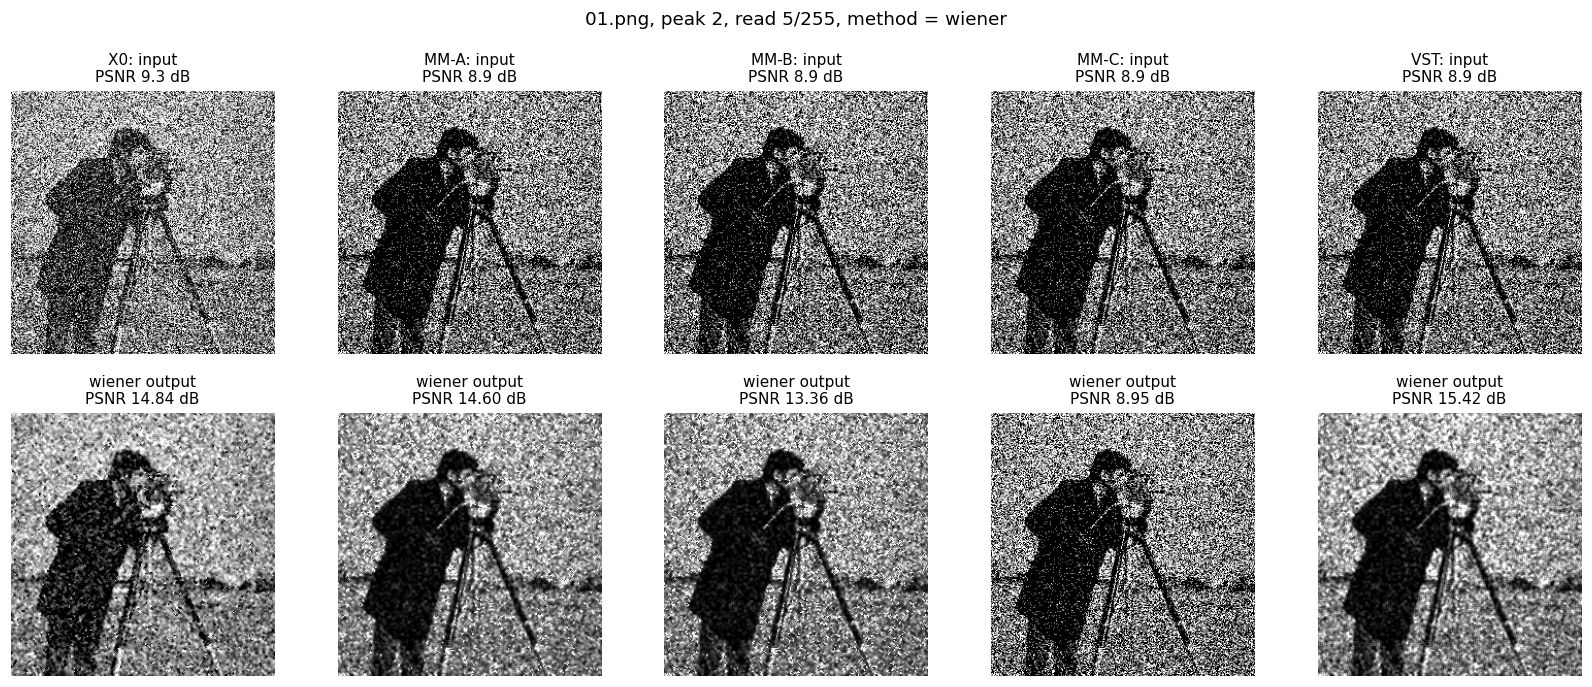

,noise,sigma_assumed,unit,PSNR out
arm,,,,
X0,awgn,123.14,/255,14.84
MM-A,pg,123.14,/255,14.60
MM-B,pg,100.37,/255,13.36
MM-C,pg,5.00,/255,8.95
VST,pg,1.00,GAT units,15.42


In [4]:
METHOD = "wiener"
setting = Setting("pg", f"pg_p{PEAK}_r{SIGMA_READ_255}", peak=float(PEAK), sigma_read=sr)
cases, est = build_cases(x, name, setting, list(ARMS), SEED, 0)

fig, ax = plt.subplots(2, len(cases), figsize=(3 * len(cases), 6.2))
table = []
for j, c in enumerate(cases):
    if c.pipeline == "vst":
        out = vst_pipeline(METHOD, c.z, c.alpha, c.sigma_read, c.vst_inverse)
    else:
        out = denoise(METHOD, c.z, params_for(METHOD, c.sigma_assumed, "image"))
    ax[0, j].imshow(np.clip(c.z, 0, 1), cmap="gray", vmin=0, vmax=1)
    ax[0, j].set_title(f"{c.arm}: input\nPSNR {psnr(x, np.clip(c.z, 0, 1)):.1f} dB")
    ax[1, j].imshow(out, cmap="gray", vmin=0, vmax=1)
    ax[1, j].set_title(f"{METHOD} output\nPSNR {psnr(x, out):.2f} dB")
    for a in ax[:, j]: a.axis("off"); a.grid(False)
    table.append({"arm": c.arm, "noise": c.noise_type, "sigma_assumed": c.sigma_assumed * (255 if c.pipeline == "direct" else 1),
                  "unit": "/255" if c.pipeline == "direct" else "GAT units", "PSNR out": psnr(x, out)})
plt.suptitle(f"{name}, peak {PEAK}, read {SIGMA_READ_255}/255, method = {METHOD}", y=1.0)
plt.tight_layout(h_pad=2.5); plt.show()
pd.DataFrame(table).round(2).set_index("arm")

## 4. Inverse GAT: why the exact inverse exists

After denoising in the GAT domain we must map back. The algebraic inverse is biased at low counts. The closed form is a good approximation. The exact unbiased inverse removes the bias (what remains is the Monte Carlo noise floor of this check, about 1e-4). Bias is shown as `|x_hat - x|` on a log axis.

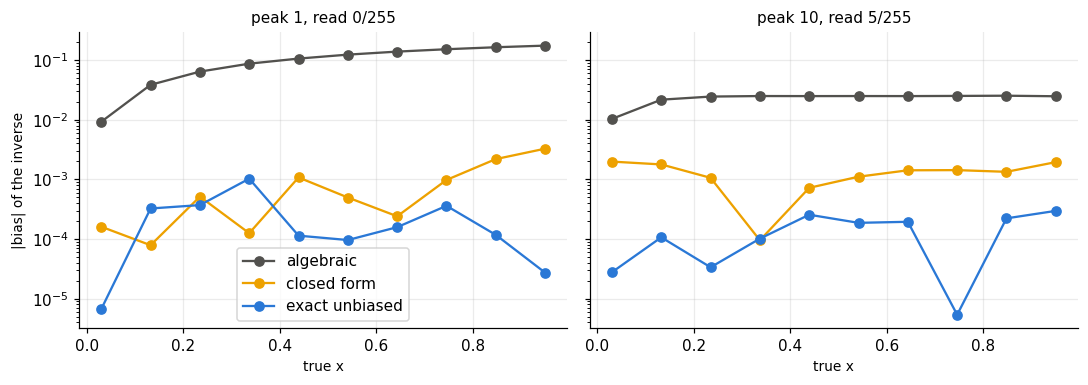

In [5]:
xs = np.linspace(0.03, 0.95, 10)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, (p, r) in zip(ax, [(1, 0), (10, 5)]):
    res = inverse_bias_curve(xs, alpha_from_peak(p), r / 255, np.random.default_rng(3), n_samples=2_000_000)
    for key, col, lab in [("algebraic", "#52514e", "algebraic"), ("closed_form", COL["MM-C"], "closed form"), ("exact", COL["X0"], "exact unbiased")]:
        a.semilogy(xs, np.abs(res[key] - xs) + 1e-6, "o-", color=col, label=lab)
    a.set_title(f"peak {p}, read {r}/255"); a.set_xlabel("true x")
ax[0].set_ylabel("|bias| of the inverse"); ax[0].legend()
plt.tight_layout(); plt.show()

## 5. The harness, live

A small run: Set12, first 3 images, 4 methods, a reduced grid (`quick` preset). It writes to `results/phase2_demo.csv`, never to the full results file. Methods that are not implemented yet (`wavelet`, `nlm`, `bm3d`) would be skipped automatically.

In [6]:
quick = apply_preset(cfg, "quick")
print("grid:", quick["noise"])
summary = run_experiments(quick, datasets=["set12"], methods=["mean", "gaussian", "median", "wiener"],
                          arms=list(ARMS), out=ROOT / "results" / "phase2_demo.csv", max_images=3, overwrite=True)
demo = pd.read_csv(ROOT / "results" / "phase2_demo.csv")
print(summary["written"], "rows written")
demo.head(8)

grid: {'awgn': {'sigmas_255': [25]}, 'poisson_gaussian': {'peaks': [2, 10], 'sigmas_255': [0, 10]}}


experiments:   0%|          | 0/252 [00:00<?, ?run/s]

experiments:   3%|▎         | 7/252 [00:00<00:03, 69.04run/s]

experiments:   7%|▋         | 18/252 [00:00<00:02, 90.94run/s]

experiments:  11%|█         | 28/252 [00:00<00:02, 82.88run/s]

experiments:  15%|█▍        | 37/252 [00:00<00:02, 79.36run/s]

... (22 outputs left out)

experiments:  99%|█████████▉| 250/252 [00:03<00:00, 82.70run/s]

experiments: 100%|██████████| 252/252 [00:03<00:00, 77.93run/s]

252 rows written


,dataset,image,method,arm,noise_type,sigma_true,peak,sigma_read,sigma_assumed,repeat,seed,psnr,ssim,time_s,noisy_psnr
0,set12,01.png,mean,M0,awgn,0.098039,NaN,NaN,0.098039,0,2026,22.727464,0.638176,0.000893,20.138127
1,set12,01.png,gaussian,M0,awgn,0.098039,NaN,NaN,0.098039,0,2026,23.487421,0.684933,0.000867,20.138127
2,set12,01.png,median,M0,awgn,0.098039,NaN,NaN,0.098039,0,2026,23.208146,0.615440,0.022294,20.138127
3,set12,01.png,wiener,M0,awgn,0.098039,NaN,NaN,0.098039,0,2026,25.941367,0.585081,0.003352,20.138127
4,set12,01.png,mean,X0,awgn,0.482486,2.0,0.0,0.482486,0,2026,19.407315,0.309508,0.000620,6.347066
5,set12,01.png,gaussian,X0,awgn,0.482486,2.0,0.0,0.482486,0,2026,19.994362,0.460512,0.001158,6.347066
6,set12,01.png,median,X0,awgn,0.482486,2.0,0.0,0.482486,0,2026,18.611489,0.263236,0.039073,6.347066
7,set12,01.png,wiener,X0,awgn,0.482486,2.0,0.0,0.482486,0,2026,14.851643,0.179107,0.003433,6.347066


In [7]:
# what a result row looks like once aggregated: mean PSNR per arm and method on the quick grid
demo.groupby(["arm", "method"]).psnr.mean().unstack("method").round(2)

method,gaussian,mean,median,wiener
arm,,,,
M0,25.48,24.71,24.99,26.38
MM-A,21.72,21.30,18.16,17.22
MM-B,21.84,21.30,18.16,16.53
MM-C,17.10,18.56,15.93,11.25
VST,21.83,21.23,18.62,17.81
X0,21.72,21.32,20.64,17.47


## 6. Full benchmark results

Read from `results/phase2_results.csv` (written by `python run_experiments.py`). Set `DATASETS` to focus on one dataset.

In [8]:
FULL = ROOT / "results" / "phase2_results.csv"
EST = ROOT / "results" / "phase2_results_estimates.csv"
DATASETS = None            # e.g. ["set12"]; None = all datasets in the file
assert FULL.exists(), "run the full benchmark first: python run_experiments.py --methods mean gaussian median wiener --out results/phase2_results.csv"
df = pd.read_csv(FULL)
if DATASETS: df = df[df.dataset.isin(DATASETS)]
print(f"{len(df):,} rows | methods: {sorted(df.method.unique())}")
print("images per dataset:", df.groupby("dataset").image.nunique().to_dict())
df.groupby(["dataset", "arm"]).size().unstack()

32,448 rows | methods: ['gaussian', 'mean', 'median', 'wiener']
images per dataset: {'bsd68': 68, 'kodak24': 24, 'set12': 12}


arm,M0,MM-A,MM-B,MM-C,VST,X0
dataset,,,,,,
bsd68,816,4080,4080,4080,4080,4080
kodak24,288,1440,1440,1440,1440,1440
set12,144,720,720,720,720,720


### 6.1 Matched AWGN (arm M0): do our numbers look like the literature?

In [9]:
m0 = df[df.arm == "M0"].assign(sigma=lambda d: (d.sigma_true * 255).round().astype(int))
m0.groupby(["dataset", "sigma", "method"]).psnr.mean().unstack("method").round(2)

method         gaussian   mean  median  wiener
dataset sigma                                 
bsd68   15        26.89  27.02   26.90   29.13
        25        25.20  24.50   24.56   25.88
        50        23.22  22.93   22.67   21.28
kodak24 15        27.68  27.80   27.64   29.58
        25        25.98  25.20   25.18   26.24
        50        24.04  23.64   23.28   21.42
set12   15        27.22  27.52   27.80   29.51
        25        25.32  24.61   24.92   26.15
        50        22.89  22.78   22.66   21.35

### 6.2 Mismatch penalty and VST gain

Per image and setting: **penalty = PSNR(X0) - PSNR(MM-A)**, how much worse the method is on PG noise than on Gaussian noise of the same total variance, when told the right average level. **VST gain = PSNR(VST) - PSNR(MM-A)**. Positive penalty = the method suffers from the noise shape. Blue is below zero, orange above.

Expect about 0 for the linear filters (mean, Gaussian, and nearly Wiener): the expected squared error of a linear filter depends only on the noise variance, not on whether it is signal dependent. Non-linear methods (median here; NLM, BM3D, wavelet later) are where the noise shape can matter.

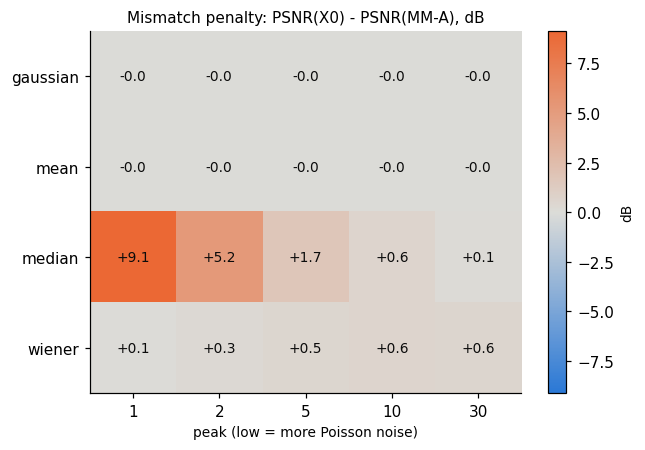

peak,1.0,2.0,5.0,10.0,30.0
method,,,,,
gaussian,-0.04,-0.02,-0.01,-0.01,-0.01
mean,-0.04,-0.03,-0.02,-0.02,-0.01
median,9.12,5.25,1.70,0.62,0.12
wiener,0.07,0.27,0.49,0.58,0.55


In [10]:
pg = df[df.peak.notna()]
wide = pg.pivot_table(index=["dataset", "image", "method", "peak", "sigma_read"], columns="arm", values="psnr")
wide["penalty"] = wide["X0"] - wide["MM-A"]
wide["vst_gain"] = wide["VST"] - wide["MM-A"]
wide["estimation_cost"] = wide["MM-A"] - wide["MM-B"]   # what a blind sigma estimate costs on top
wide = wide.reset_index()

def heat(col, title):
    t = wide.groupby(["method", "peak"])[col].mean().unstack("peak")
    lim = np.nanmax(np.abs(t.values))
    fig, a = plt.subplots(figsize=(6, 0.7 * len(t) + 1.4))
    im = a.imshow(t.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto"); a.grid(False)
    a.set_xticks(range(t.shape[1]), [f"{int(p)}" for p in t.columns]); a.set_yticks(range(t.shape[0]), t.index)
    a.set_xlabel("peak (low = more Poisson noise)"); a.set_title(title)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            a.text(j, i, f"{t.values[i, j]:+.1f}", ha="center", va="center", fontsize=9, color="#0b0b0b")
    plt.colorbar(im, ax=a, label="dB"); plt.tight_layout(); plt.show()
    return t.round(2)

heat("penalty", "Mismatch penalty: PSNR(X0) - PSNR(MM-A), dB")

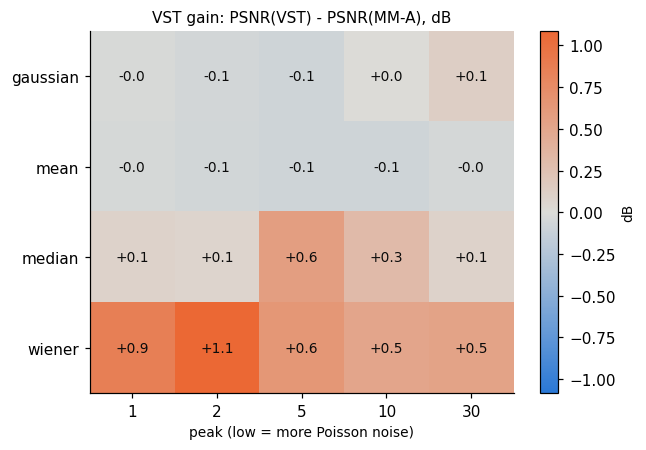

peak,1.0,2.0,5.0,10.0,30.0
method,,,,,
gaussian,-0.03,-0.06,-0.08,0.01,0.12
mean,-0.04,-0.06,-0.08,-0.08,-0.05
median,0.09,0.07,0.57,0.31,0.09
wiener,0.86,1.09,0.64,0.50,0.53


In [11]:
heat("vst_gain", "VST gain: PSNR(VST) - PSNR(MM-A), dB")

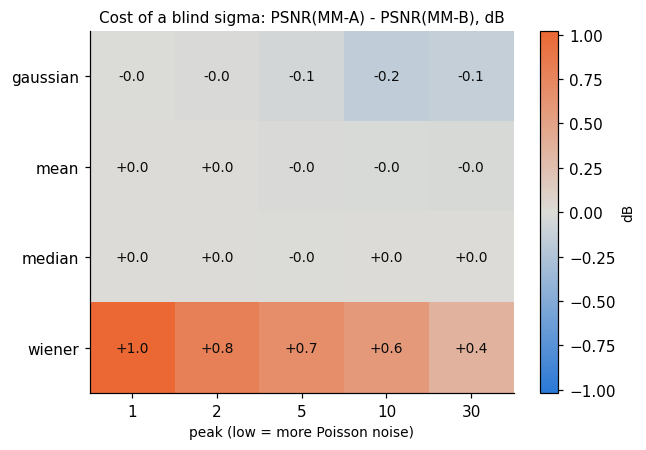

peak,1.0,2.0,5.0,10.0,30.0
method,,,,,
gaussian,-0.00,-0.01,-0.05,-0.16,-0.13
mean,0.00,0.00,-0.01,-0.02,-0.03
median,0.00,0.00,-0.00,0.00,0.01
wiener,1.02,0.80,0.68,0.58,0.36


In [12]:
heat("estimation_cost", "Cost of a blind sigma: PSNR(MM-A) - PSNR(MM-B), dB")

### 6.3 Mean PSNR per arm, by peak

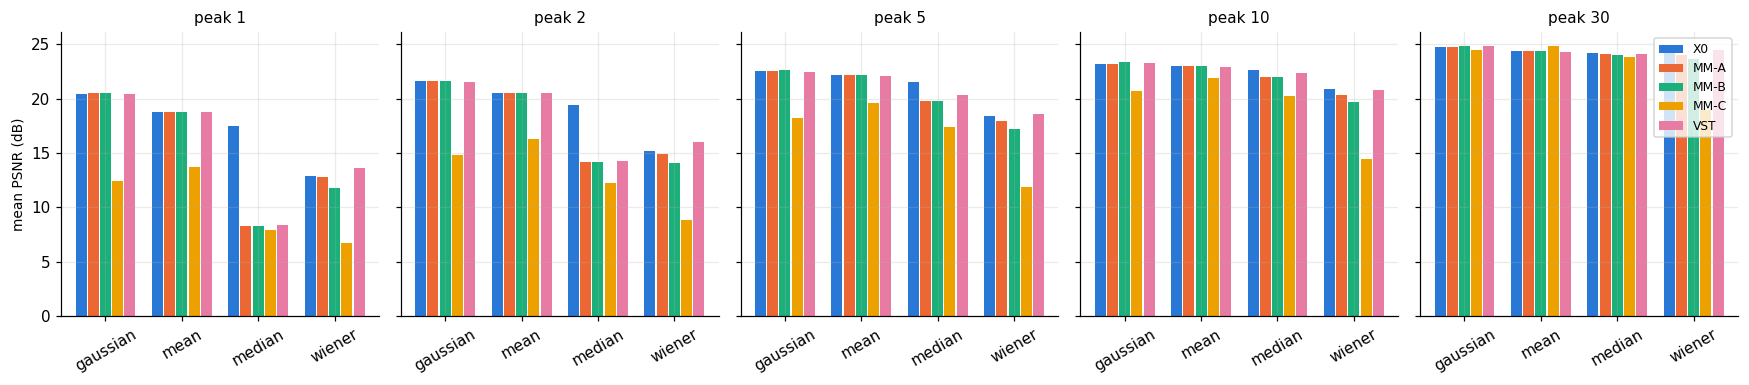

arm               X0   MM-A   MM-B   MM-C    VST
peak method                                     
1.0  gaussian  20.46  20.50  20.50  12.44  20.46
     mean      18.77  18.81  18.81  13.74  18.77
     median    17.46   8.34   8.34   7.89   8.43
     wiener    12.86  12.79  11.77   6.72  13.65
2.0  gaussian  21.60  21.62  21.63  14.81  21.56
     mean      20.51  20.54  20.54  16.29  20.48
     median    19.45  14.20  14.20  12.22  14.27
     wiener    15.18  14.91  14.11   8.85  15.99
5.0  gaussian  22.55  22.56  22.61  18.20  22.48
     mean      22.16  22.18  22.19  19.63  22.10
     median    21.50  19.80  19.80  17.37  20.37
     wiener    18.42  17.93  17.25  11.92  18.57
10.0 gaussian  23.22  23.23  23.39  20.74  23.24
     mean      22.96  22.98  23.00  21.93  22.90
     median    22.63  22.01  22.00  20.27  22.31
     wiener    20.87  20.30  19.72  14.50  20.80
30.0 gaussian  24.73  24.74  24.87  24.43  24.86
     mean      24.34  24.35  24.38  24.87  24.30
     median    24.18  24.06  24.05  23.84  24.15
     wiener    24.53  23.98  23.62  18.97  24.50

In [13]:
arms_pg = ["X0", "MM-A", "MM-B", "MM-C", "VST"]
t = pg.groupby(["peak", "method", "arm"]).psnr.mean().unstack("arm")[arms_pg]
peaks = sorted(pg.peak.unique()); methods = sorted(pg.method.unique())
fig, ax = plt.subplots(1, len(peaks), figsize=(3.2 * len(peaks), 3.6), sharey=True)
w = 0.8 / len(arms_pg)
for a, p in zip(np.atleast_1d(ax), peaks):
    for k, arm in enumerate(arms_pg):
        a.bar(np.arange(len(methods)) + k * w, [t.loc[(p, m), arm] for m in methods], w * 0.9, color=COL[arm], label=arm)
    a.set_xticks(np.arange(len(methods)) + 0.4 - w / 2, methods, rotation=30); a.set_title(f"peak {int(p)}")
np.atleast_1d(ax)[0].set_ylabel("mean PSNR (dB)"); np.atleast_1d(ax)[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()
t.round(2)

### 6.4 Runtime and noise-level estimates

In [14]:
df.groupby(["dataset", "method"]).time_s.mean().mul(1000).unstack("method").round(1).rename_axis("mean ms per call")

method,gaussian,mean,median,wiener
mean ms per call,,,,
bsd68,2.8,1.7,65.6,12.8
kodak24,5.0,3.1,108.9,21.8
set12,3.5,2.3,63.6,12.1


In [15]:
est = pd.read_csv(EST)
(est.groupby(["peak", "sigma_read"])[["sigma_eq", "sigma_blind", "sigma_read_only"]].mean() * 255).round(1).rename(
    columns={"sigma_eq": "A: sigma_eq", "sigma_blind": "B: blind", "sigma_read_only": "C: read only"}).rename_axis(index={"sigma_read": "read (0-1 units)"})

A: sigma_eq  B: blind  C: read only
peak read (0-1 units)                                     
1.0  0.000000                168.1     145.1           1.0
     0.019608                168.2     139.0           5.0
     0.039216                168.4     139.5          10.0
2.0  0.000000                118.9     105.7           1.0
     0.019608                119.0     104.4           5.0
     0.039216                119.3     104.8          10.0
5.0  0.000000                 75.2      67.9           1.0
     0.019608                 75.4      68.0           5.0
     0.039216                 75.9      68.7          10.0
10.0 0.000000                 53.2      48.5           1.0
     0.019608                 53.4      48.8           5.0
     0.039216                 54.1      49.7          10.0
30.0 0.000000                 30.7      28.6           1.0
     0.019608                 31.1      29.1           5.0
     0.039216                 32.3      30.7          10.0

## Caveats to keep in mind when presenting

- The mean / Gaussian / median parameter rules in `experiments/params.py` are **temporary** until the parameter policy of Part B is final. Numbers for those methods can change.
- Only the four implemented methods are in the results. Wavelet, NLM and BM3D are skipped by the harness until Part B lands them; `--resume` adds them without redoing the rest.
- Rule A uses the clean image to set the sigma level (oracle); rule B is the realistic view.
- Noise is not clipped (PG noise can be negative); outputs are clipped to [0, 1] before PSNR / SSIM.